# Лабораторная работа №1: регрессия

## Первичный анализ

(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


count    6497.000000
mean        5.818378
std         0.873255
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         9.000000
Name: quality, dtype: float64

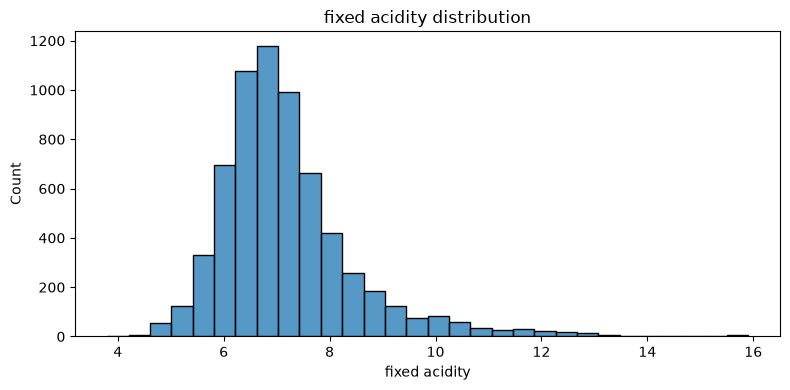

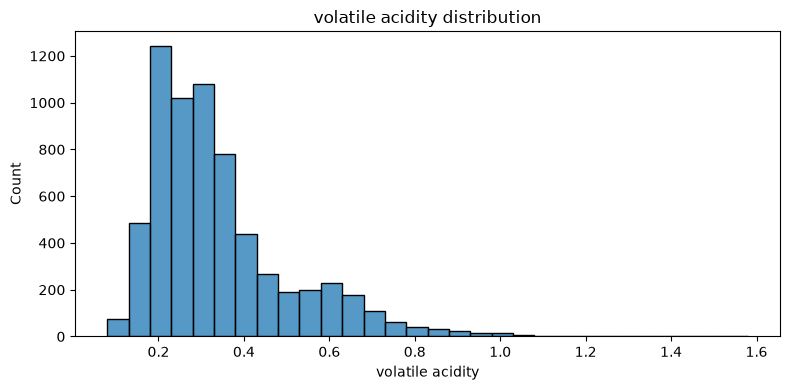

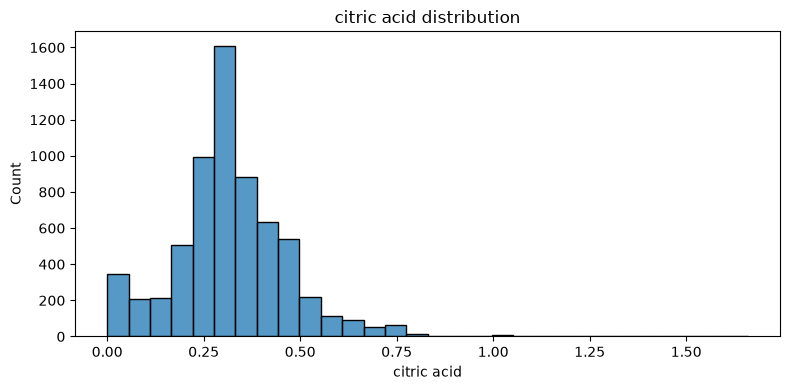

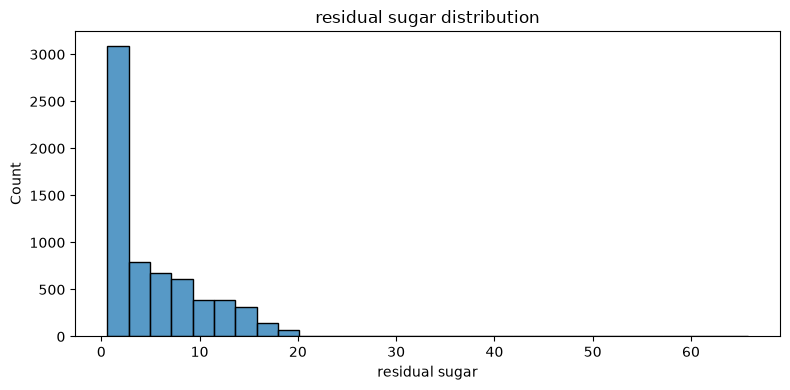

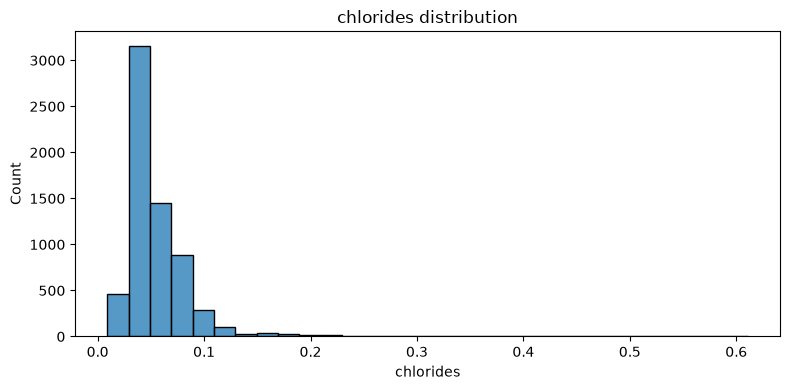

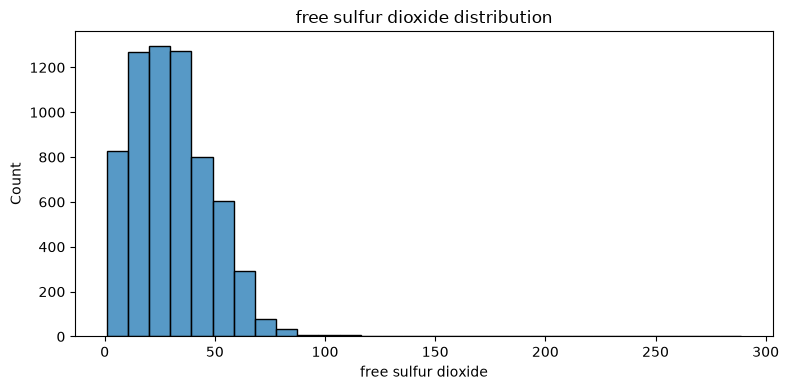

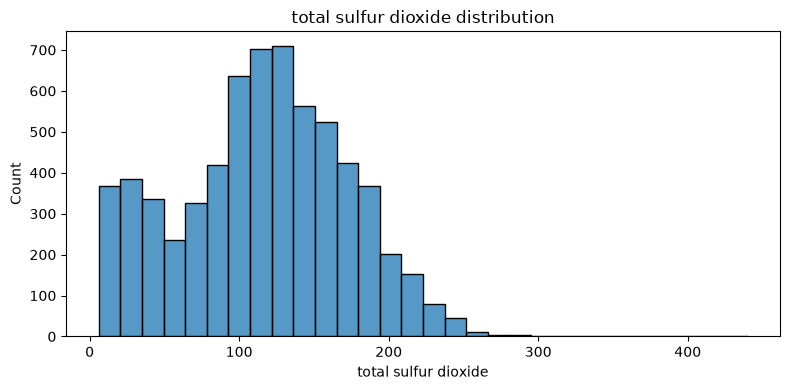

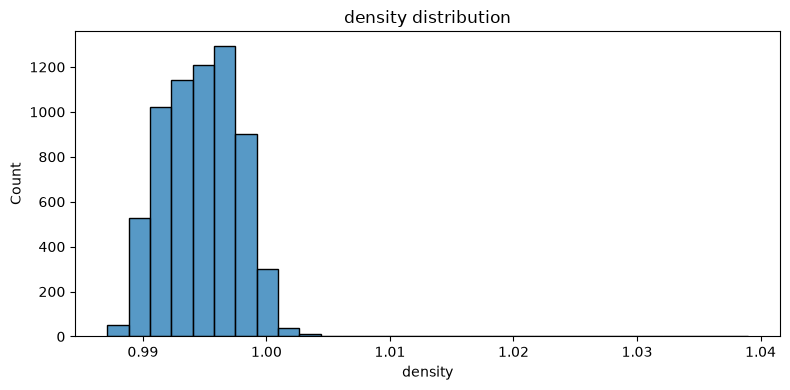

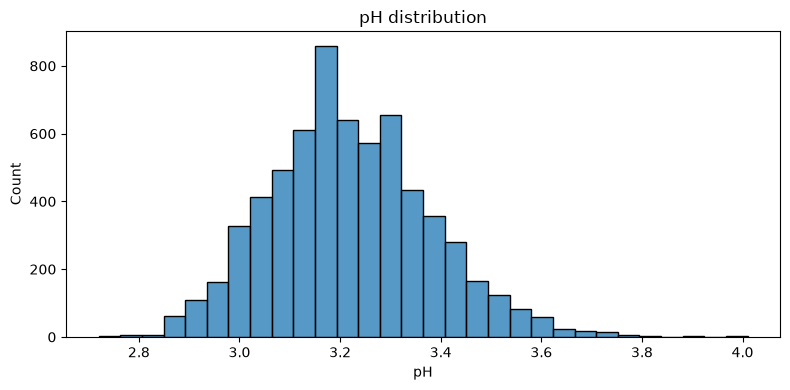

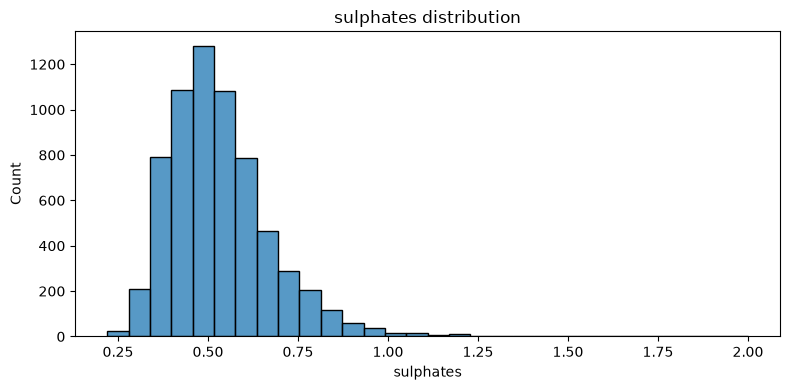

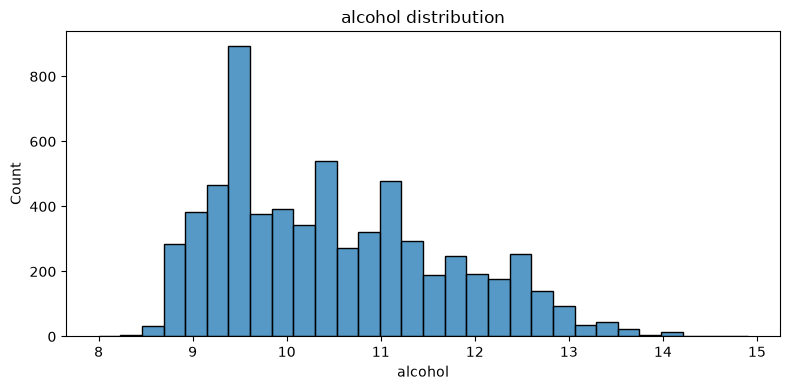

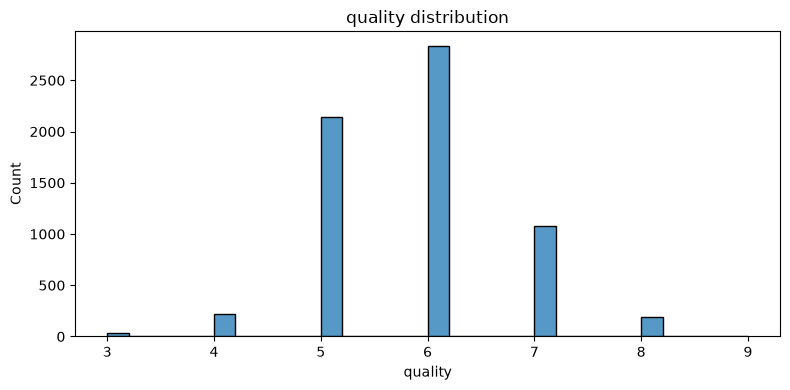

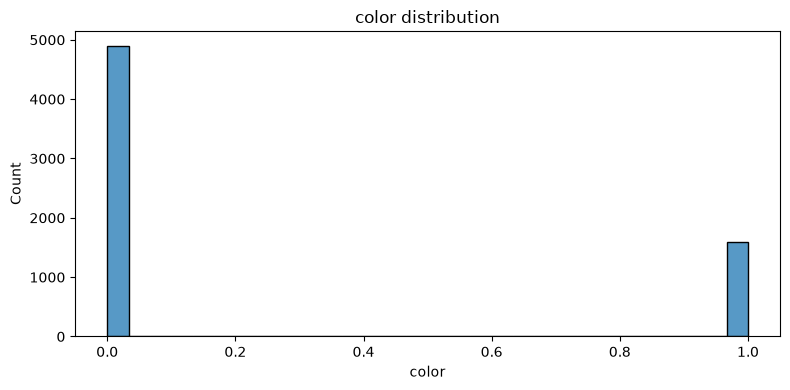

Dublicates count:


np.int64(1177)

Pearson correlation coefficients:
fixed acidity          -0.076743
volatile acidity       -0.265699
citric acid             0.085532
residual sugar         -0.036980
chlorides              -0.200666
free sulfur dioxide     0.055463
total sulfur dioxide   -0.041385
density                -0.305858
pH                      0.019506
sulphates               0.038485
alcohol                 0.444319
color                  -0.119323
Name: quality, dtype: float64


In [316]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

def show_column_distribution(column: str):
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(x=df[column], bins=30, ax=ax)
    ax.set_title(f"{column} distribution")
    plt.tight_layout()
    plt.show()

df_red = pd.read_csv("datasets/winequality-red.csv", sep=";")
df_white = pd.read_csv("datasets/winequality-white.csv", sep=";")

df_red['color'] = 1
df_white['color'] = 0

df = pd.concat((df_red, df_white), ignore_index=True)
    
print(df.shape)
display(df.head())
display(df["quality"].describe())
for c in df.columns:
    show_column_distribution(c)
print("Dublicates count:")
display(df.duplicated().sum())
print("Pearson correlation coefficients:")
print(df.corr()['quality'].drop('quality'))

Видно, что quality принимает целые значения от 3 до 9, стандартное отклонение маленькое. Это означает, что у подавляющей части объектов quality это 5 и 6, и модель в основном будет учиться предстказывать именно их.

Сильной корреляции ни с каким признаком у quality нет. Средняя корреляция наблюдается с признаками alcohol, положительная, и density, отрицательная, то есть чем больше в вине алкоголя, тем оценка качества выше, и чем выше плотность, тем quality ниже.

Слабая корреляция с quality наблюдается у признаков chlorides и volatile acidity, а признаки fixed acidity, citric acid, residual sugar, free sulfur dioxide, total sulfur dioxide, pH и sulphates линейной зависимости с quality практически не имеют.

18% датасетов являются копиями существующих, их нужно исключить для лучшего обучения.

## Подготовка выборок

In [317]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

df = df.drop_duplicates()

y = df["quality"]
X = df.drop(columns=["quality"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

Дубликаты были удалены, поскольку они являются обычными повторами измерений.

80% данных используются для train, 20% - для test. Это обусловлено тем, что размер датасета небольшой, поэтому стоит оставить значимую часть выборки для test, но также нужно большое кол-во данных для train, чтобы покрывать как можно больше случаев.

Если бы модель обучалась на одной и той же выборке, то она бы переобучилась и идеально запомнила ответы на примеры из train, но имела бы гигантскую ошибку на других, отличающихся данных.

## Baseline

In [318]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import Pipeline

def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)


def mae(y_true, y_pred):
    return mean_absolute_error(y_true, y_pred)


rows = []

baseline = Pipeline([
    ("model", DummyRegressor(strategy="mean"))
])
baseline.fit(X_train, y_train)

pred_base = baseline.predict(X_test)

rows.append({
    "model": "Baseline",
    "RMSE": rmse(y_test, pred_base),
    "MAE": mae(y_test, pred_base)
})

print("Baseline RMSE:", rmse(y_test, pred_base))
print("Baseline MAE:", mae(y_test, pred_base))

Baseline RMSE: 0.8675790772750018
Baseline MAE: 0.6942255780428516


## Метрики
Для лабораторной работы используются метрики RMSE, основная метрика, и MAE.
MAE показывает среднее отклонение по модулю предсказания модели от реального значения целеовой переменной.
RMSE вычисляет стандартное отклонение ошибок, то есть показывает, насколько сильно предсказания разбросаны вокруг реальных значений.
Важное отличие RMSE от MAE в том, что при подсчёте RMSE берётся сумма квадратов ошибок перед извлечением корня, а квадратичная функция, как известно, растёт быстрее линейной, которой является сложение абсолютных значений ошибок в MAE, поэтому RMSE сильнее реагирует на большие ошибки.
Следовательно, RMSE сильно отличается от MAE, это значит, что на каких-то данных модель сильно ошибается, то есть есть смысл дополнительно обработать тестовую выборку, проверив её на выбросы, например.

## Linear Regression
Прологарифмируем признаки скошенные вправо, а также построим полиномиальные признаки второй степени для всех столбцов, кроме color, ведь он бинарный, и, кроме увеличения размерности вектора признаков, будет иметь значение идентичное своему квадрату, что приводит к мультиколлинеарности. Так же исключим признак density из-за его средней корреляции с другими признаки, как показал перебор признаков для PolynommialFeatures.

In [319]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    FunctionTransformer,
    PolynomialFeatures
)

def create_preprocessor():
    skewness = X.skew()
    skewed_columns = skewness[skewness > 1].index.tolist()

    return ColumnTransformer(
        [
            (
                "log",
                FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                [col for col in skewed_columns if col != "color"]
            ),
            (
                "poly",
                PolynomialFeatures(2, include_bias=False),
                [col for col in X.columns if col != "density" and col != "color"]
            )
        ],
        remainder="passthrough",
    )

Дополнительно будем проводить L1 и L2 регуляризации. Найдём оптимальный коэффициент alpha для ridge и lasso регрессий. Для этого переберём значения из логичных интервалов и построим графики зависимости значения метрики RMSE от коэффициента alpha.

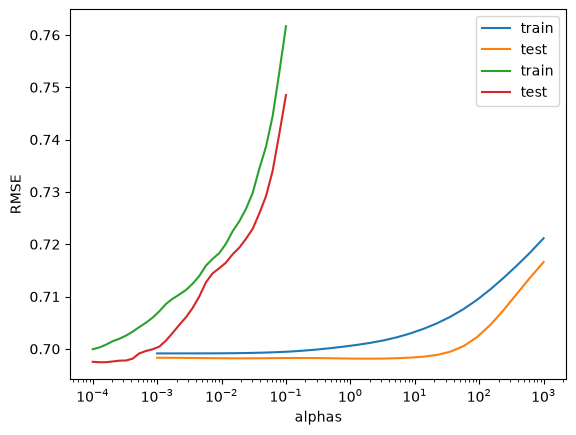

In [320]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler

def draw_alpha(alphas, model_class, model_name, **kwargs):
    train_rmse, test_rmse = [], []

    for a in alphas:
        model = Pipeline([
            ("preprocessing", create_preprocessor()),
            ("scaler", StandardScaler()),
            ("model", model_class(alpha=a, **kwargs))
        ])
        
        model.fit(X_train, y_train)
        
        train_rmse.append(rmse(y_train, model.predict(X_train)))
        test_rmse.append(rmse(y_test, model.predict(X_test)))

    plt.semilogx(alphas, train_rmse, label="train")
    plt.semilogx(alphas, test_rmse, label="test")
    plt.legend(); plt.xlabel("alphas"); plt.ylabel("RMSE")

draw_alpha(np.logspace(-3, 3, 30), Ridge, "Ridge")
draw_alpha(np.logspace(-4, -1, 30), Lasso, "Lasso", max_iter=100000)

Как и ожидалось, при увеличении альфа ошибка на тесте сначала улучшается, а затем - ухудшается.
Изменение ошибки ridge-регрессии, как видно на графике, незначительно, а при $alpha > 10^{1}$ модель недообучается. Было принято решения взять $alpha = 0.8$ для $RMSE < 0.7$ и на train, и на test.
Lasso как правило требует коэффициент значительно ниже. В данном случае коэффициент меньше чем $10^{-4}$ требует огромное, нерациональное кол-во итераций для алгоритма оптимизации, а явное недообучение заметно при $alpha > 10^{-3.5}$, так что я взял $alpha = 10^{-4}$.

In [321]:
from sklearn.linear_model import LinearRegression

linreg = Pipeline([
    ("preprocessing", create_preprocessor()),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

ridge = Pipeline([
    ("preprocessing", create_preprocessor()),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=0.1))
])

lasso = Pipeline([
    ("preprocessing", create_preprocessor()),
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=0.0001, max_iter=100000))
])

for name, model in {"LinearRegression": linreg, "Ridge": ridge, "Lasso": lasso}.items():
    model.fit(X_train, y_train)

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    rows.append({
        "model": name,
        "RMSE": rmse(y_test, pred_test),
        "MAE": mae(y_test, pred_test)
    })
    
    print(f"{name} coefficients")
    print("Train RMSE:", rmse(y_train, pred_train))
    print("Test RMSE:", rmse(y_test, pred_test))
    print("Test MAE:", mae(y_test, pred_test))

    coefs = pd.Series(
        model.named_steps["model"].coef_,
        index=model[:-1].get_feature_names_out(X_train.columns)
    ).sort_values()
    display(coefs)

LinearRegression coefficients
Train RMSE: 0.6991365398980145
Test RMSE: 0.6983294547783734
Test MAE: 0.5425559922226842


log__chlorides                   -4.425223
log__volatile acidity            -4.111671
poly__chlorides pH               -1.177158
poly__volatile acidity^2         -1.166895
poly__pH^2                       -0.741870
                                    ...   
poly__total sulfur dioxide        0.685674
poly__volatile acidity alcohol    0.714787
poly__pH                          0.775947
poly__volatile acidity            4.220358
poly__chlorides                   6.565601
Length: 73, dtype: float64

Ridge coefficients
Train RMSE: 0.6994539654488212
Test RMSE: 0.6982540197412666
Test MAE: 0.542442532335129


log__volatile acidity            -3.007214
poly__chlorides pH               -1.133364
poly__volatile acidity^2         -0.850824
poly__pH^2                       -0.688679
poly__residual sugar pH          -0.640982
                                    ...   
poly__total sulfur dioxide        0.574140
poly__volatile acidity alcohol    0.716540
poly__pH                          0.724235
poly__chlorides                   2.052677
poly__volatile acidity            2.786985
Length: 73, dtype: float64

Lasso coefficients
Train RMSE: 0.6999400351110477
Test RMSE: 0.6975342895634985
Test MAE: 0.5428681685262912


log__volatile acidity               -2.336901
poly__chlorides pH                  -0.980648
poly__volatile acidity^2            -0.649702
poly__pH^2                          -0.577049
poly__residual sugar pH             -0.499413
                                       ...   
poly__free sulfur dioxide alcohol    0.458544
poly__volatile acidity alcohol       0.650194
poly__pH                             0.656702
poly__chlorides                      1.352826
poly__volatile acidity               2.048444
Length: 73, dtype: float64

Как и ожидалось, RMSE на train и test близкий, то есть модель не переобучилась.

Для сравнения коэффициентов признаков ко всем ним было применено масштабирование, чтобы относительное сравнение было корректным. Также масштабирование делает штрафы Lasso и Ridge более логичными, иначе, при использовании значений коэффициентов, зависящих от абсолютных, безразмерных значений признаков, они бы штрафовались некорректно.

Признаком, однозначно ухудшающим качество вина больше всего оказалось взаимодействие chlorides и pH.
Зависимость от chlorides и volatile acidity оказалась нелинейная. Небольшое кол-во хлоридов в комбинации с чем-то может сказаться положительно, судя по влиянию квадратичного члена poly_chlorides, но когда их много, они сильно портят вино. Аналогично с volatile acidity. log_chlorides сильно уменьшился у Ridge и, скорее всего, занулился у Lasso из-за мультиколлинеарности с другими важными признаками.

## Random Forest Regressor
Так как деревья сами могут улавливать нелинейные зависимости, а также никак не чувствую масштаб, препроцессинг для этой модели можно не применять.

In [322]:
from sklearn.ensemble import RandomForestRegressor

random_forest = Pipeline([("model", RandomForestRegressor(random_state=RANDOM_STATE))])

random_forest.fit(X_train, y_train)

pred_train = random_forest.predict(X_train)
pred_test = random_forest.predict(X_test)

rows.append({
    "model": "RandomForestRegressor",
    "RMSE": rmse(y_test, pred_test),
    "MAE": mae(y_test, pred_test)
})

print("Random Forest Regressor")
print("Train RMSE:", rmse(y_train, pred_train))
print("Test RMSE:", rmse(y_test, pred_test))
print("Test MAE:", mae(y_test, pred_test))

importances = pd.Series(
    random_forest.named_steps['model'].feature_importances_,
    index=X.columns
).sort_values()
display(importances)


Random Forest Regressor
Train RMSE: 0.2592917080232688
Test RMSE: 0.6647832339344163
Test MAE: 0.5086560150375941


color                   0.001200
citric acid             0.056612
density                 0.058153
fixed acidity           0.059084
chlorides               0.060502
residual sugar          0.062697
pH                      0.070447
total sulfur dioxide    0.074380
sulphates               0.083231
free sulfur dioxide     0.094325
volatile acidity        0.115679
alcohol                 0.263689
dtype: float64

В отличие от линейной регрессии, случайный лес подтвердил корреляцию качества с признаком alcohol. Линейная регрессия не смогла это выявить из-за огромного количества других признаков, полагаясь на полиномы и логарифмы, чего не нужно random forest, благодаря древовидной структуре, что позволяет улавливать нелинейные зависимости из исходных признаков. Остальные признаки имеют умеренное влияние, volatile acidity на втором месте, что схоже с выводами, которые мы получили при анализе результатов линейной регрессии.

Также можно отметить, что признак цвета оказался абсолютно неважным.

## Gradient Boosting Regressor

In [323]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting = Pipeline([
    ('model', GradientBoostingRegressor(
        random_state = RANDOM_STATE
        )
    )
])

gradient_boosting.fit(X_train, y_train)

pred_train= gradient_boosting.predict(X_train)
pred_test= gradient_boosting.predict(X_test)

rows.append({
    "model": "GradientBoostingRegressor",
    "RMSE": rmse(y_test, pred_test),
    "MAE": mae(y_test, pred_test)
})

print("Gradient boosting")
print("Train RMSE:", rmse(y_train, pred_train))
print("Test RMSE:", rmse(y_test, pred_test))
print("Test MAE:", mae(y_test, pred_test))

importances = pd.Series(
    gradient_boosting.named_steps['model'].feature_importances_,
    index=X.columns
).sort_values()
display(importances)

Gradient boosting
Train RMSE: 0.642578925646506
Test RMSE: 0.6859516515114296
Test MAE: 0.5283206736148577


color                   0.002117
density                 0.017695
fixed acidity           0.023790
residual sugar          0.026771
citric acid             0.027128
pH                      0.028580
chlorides               0.031100
total sulfur dioxide    0.042458
sulphates               0.075444
free sulfur dioxide     0.101888
volatile acidity        0.152678
alcohol                 0.470350
dtype: float64

Расположение признаков по важности практически совпадает с random forest.

## Честное сравнение моделей
Для всех моделей был использован единый random_state, совпадающий со значением этого же параметра при разделении датасета на train и test.

In [324]:
results = pd.DataFrame(rows).sort_values("RMSE")
display(results)

,model,RMSE,MAE
4,RandomForestRegressor,0.664783,0.508656
5,GradientBoostingRegressor,0.685952,0.528321
3,Lasso,0.697534,0.542868
2,Ridge,0.698254,0.542443
1,LinearRegression,0.698329,0.542556
0,Baseline,0.867579,0.694226


Все модели обошли baseline, что как минимум говорит о том, что они имею какую-то предсказательную способность.

Random forest regressor оказался лучше остальных моделей. Он, очевидно, обошёл линейные модели, поскольку умеет улавливать нелинейные зависимости намного проще, и выиграл у gradient boosting regressor'а, поскольку тот очень чувствителен к гиперпараметрам.

## Feature Importance
Как уже было упомянуто, самыми важными признаками оказалось содержание алкоголя alcohol, volatile acidity и free sulfur dioxide, что частично совпадает с результатами первичного анализа, хотя и линейной зависимости между quality и free sulfur dioxide не оказалось вообще. Это связано с тем, что зависимость вообще не линейная и ближе к квадратичной.

Причинно-следственную связь на основе feature importances строить некорректно, поскольку это всего лишь коэффициент, показывающий то, насколько тот или иной признак помогает модели определять целевую переменную на нашей выборке.

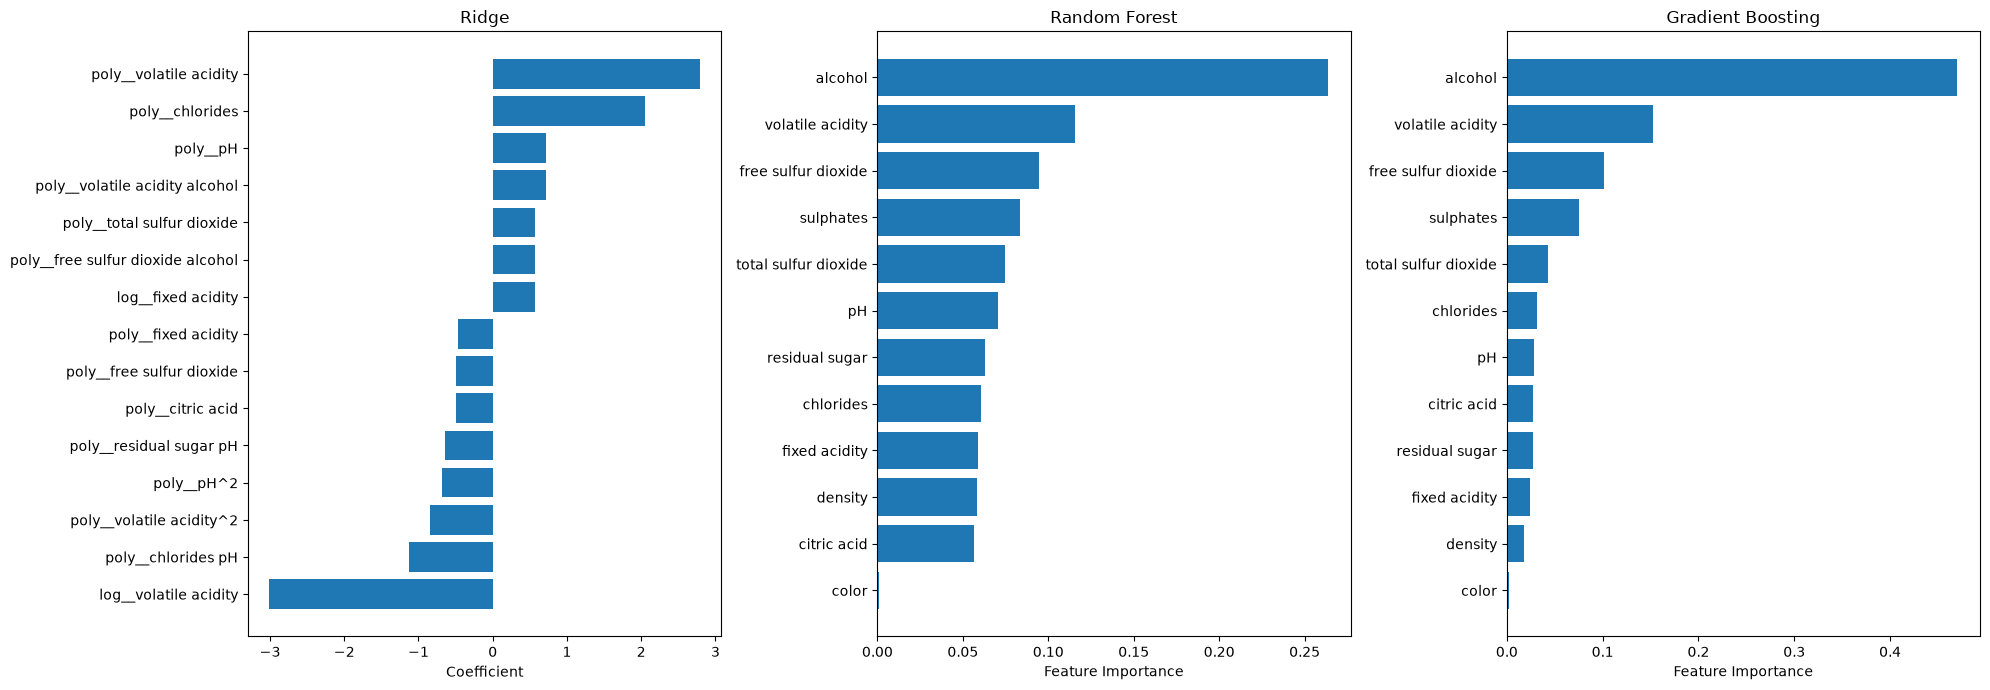

In [325]:
ridge_coefs_all = pd.Series(
    ridge.named_steps["model"].coef_,
    index=ridge[:-1].get_feature_names_out(X_train.columns)
)
top_ridge = ridge_coefs_all.reindex(ridge_coefs_all.abs().sort_values(ascending=False).index)[:15]
top_ridge = top_ridge.sort_values()


rf_importances_all = pd.Series(
    random_forest.named_steps['model'].feature_importances_,
    index=X.columns
)
rf = rf_importances_all.sort_values()

gb_importances_all = pd.Series(
    gradient_boosting.named_steps['model'].feature_importances_,
    index=X.columns
)
gb = gb_importances_all.sort_values()

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].barh(top_ridge.index, top_ridge.values)
axes[0].set_title('Ridge')
axes[0].set_xlabel('Coefficient')

axes[1].barh(rf.index, rf.values)
axes[1].set_title('Random Forest')
axes[1].set_xlabel('Feature Importance')

axes[2].barh(gb.index, gb.values)
axes[2].set_title('Gradient Boosting')
axes[2].set_xlabel('Feature Importance')

plt.tight_layout()
plt.show()

## Анализ ошибок

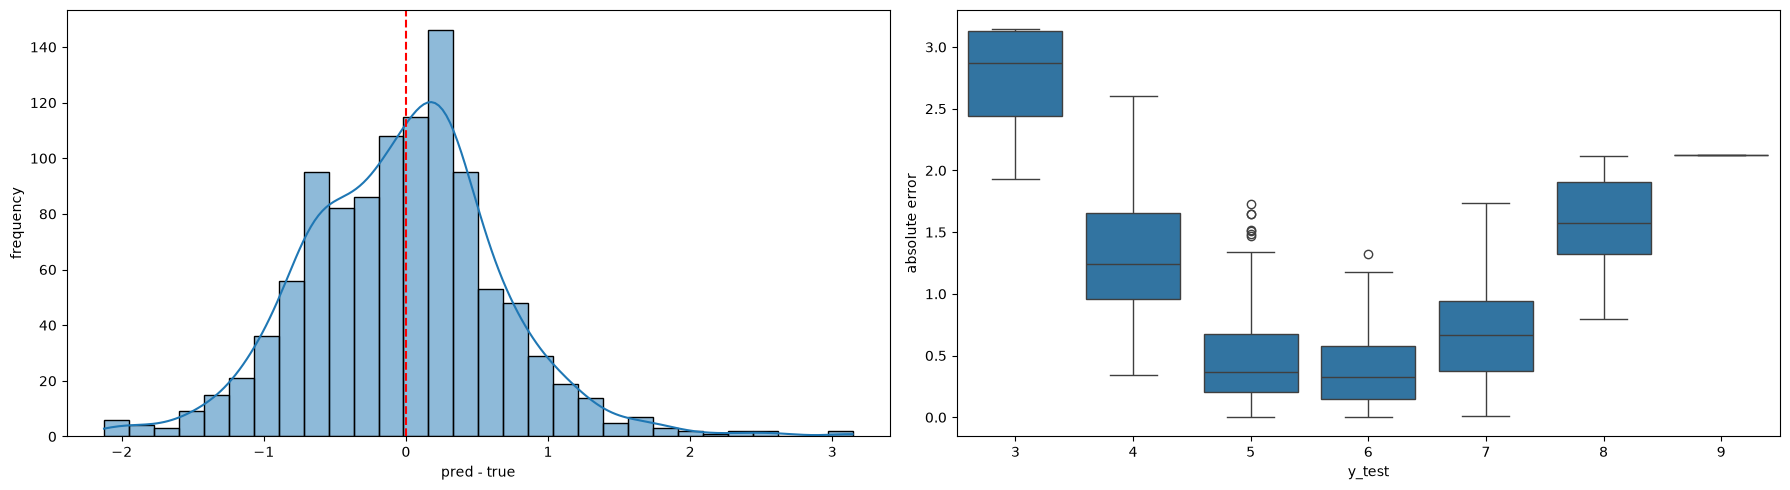

Worst predictions


,True,Pred,Error,Abs_Error,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,color
5008,3,6.142919,3.142919,3.142919,6.2,0.23,0.35,0.7,0.051,24.0,111.0,0.99160,3.37,0.43,11.0,0
2044,3,6.130533,3.130533,3.130533,7.1,0.32,0.32,11.0,0.038,16.0,66.0,0.99370,3.24,0.40,11.5,0
832,3,5.614291,2.614291,2.614291,10.4,0.44,0.42,1.5,0.145,34.0,48.0,0.99832,3.38,0.86,9.9,1
5335,4,6.605251,2.605251,2.605251,6.5,0.32,0.48,8.0,0.026,18.0,88.0,0.99144,3.22,0.79,12.7,0
5369,4,6.393996,2.393996,2.393996,7.4,0.27,0.31,2.4,0.014,15.0,143.0,0.99094,3.03,0.65,12.0,0


In [326]:
err_df = pd.DataFrame({
    'True': y_test,
    'Pred': pred_test
})
err_df['Error'] = err_df['Pred'] - err_df['True']
err_df['Abs_Error'] = err_df['Error'].abs()

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

sns.histplot(err_df['Error'], bins=30, kde=True, ax=axes[0])
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_xlabel('pred - true')
axes[0].set_ylabel('frequency')

sns.boxplot(x='True', y='Abs_Error', data=err_df, ax=axes[1])
axes[1].set_xlabel('y_test')
axes[1].set_ylabel('absolute error')

plt.tight_layout()
plt.show()

print("Worst predictions")
worst_predictions = err_df.sort_values(by='Abs_Error', ascending=False).head(5)
worst_predictions_full = worst_predictions.join(X_test) 
display(worst_predictions_full)

Ожидаемо, самая маленькая ошибка, менее 0.6, встречается на тех данных, у которых истинное качество равно 5 или 6, коих больше всего в датасете, когда как хуже всего модель справляется с предсказанием вина качества 3, 4, которых в датасете меньше всего, соответственно очень мало данных для определения зависимостей.